In [27]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import pandas as pd

# Membaca dataset
df = pd.read_csv("UrbanCabFare.csv")

# Ukuran dataset
print("========================")
print("Ukuran dataset:", df.shape)
print("========================")
# Informasi struktur dataset
print("========================")
df.info()
print("========================")

# Pemeriksaan missing value
print("========================")
print("\nMissing Value:")
print(df.isnull().sum())
print("========================")
# Pemeriksaan data duplikat
print("========================")
print("\nJumlah data duplikat:")
print(df.duplicated().sum())
print("========================")

Ukuran dataset: (1000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               1000 non-null   str    
 1   Driver_Name           985 non-null    str    
 2   City                  1000 non-null   str    
 3   Ride_Date             1000 non-null   str    
 4   Hour_of_Day           1000 non-null   int64  
 5   Day_of_Week           1000 non-null   str    
 6   Distance_km           1000 non-null   float64
 7   Traffic_Level         1000 non-null   str    
 8   Type_of_vehicle       1000 non-null   str    
 9   No_of_active_drivers  1000 non-null   int64  
 10  Ride_Requests         1000 non-null   int64  
 11  Demand_Supply_Ratio   1000 non-null   float64
 12  Trip_Duration         1000 non-null   int64  
 13  Base_Fare             1000 non-null   float64
 14  Surge_Multiplier      1000 non-null   float64
 15  Final_

In [29]:
print(df)

             User_ID        Driver_Name       City   Ride_Date  Hour_of_Day  \
0    USER-21819-Bcbf    Patrick Sanchez       Pune  05-11-2025            0   
1    USER-79402-SBvr    Meredith Barnes     Mumbai  13-10-2025            2   
2    USER-40781-yfJs         Ian Cooper  Bengaluru  16-06-2026            6   
3    USER-41316-rDOx        Amber Perez     Mumbai  15-10-2025            0   
4    USER-76483-RuXX   Kimberly Sanchez    Chennai  06-09-2025           10   
..               ...                ...        ...         ...          ...   
995  USER-58476-dLtZ          Alex Webb     Mumbai  28-06-2026           10   
996  USER-72188-xAVz  Colleen Blanchard     Mumbai  17-01-2026           10   
997  USER-50666-jAEb      Tiffany Bates     Mumbai  17-12-2025           19   
998  USER-93663-spNZ   Katherine Mullen  Hyderabad  16-10-2025           23   
999  USER-02867-fYZS      Ashlee Miller  Hyderabad  11-04-2026            9   

    Day_of_Week  Distance_km Traffic_Level Type_of_

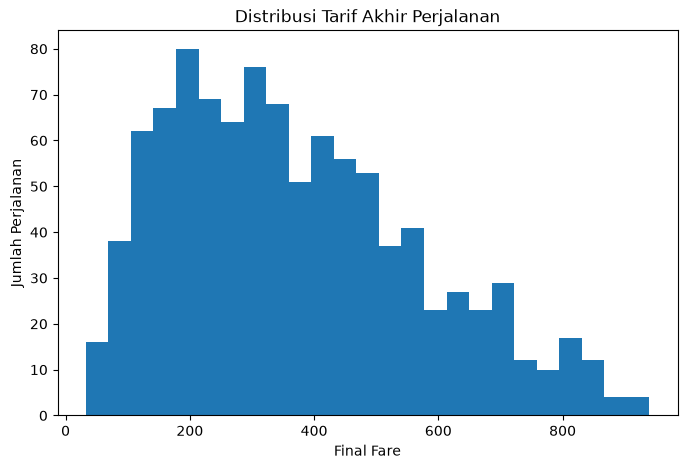

In [30]:
# ======== DISTRIBUSI TARIF AKHIR ==========

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Final_Fare"], bins=25)

plt.title("Distribusi Tarif Akhir Perjalanan")
plt.xlabel("Final Fare")
plt.ylabel("Jumlah Perjalanan")

plt.show()

City
Delhi        412.941257
Bengaluru    393.863631
Mumbai       362.644268
Chennai      352.870294
Pune         352.824330
Hyderabad    348.835548
Name: Final_Fare, dtype: float64


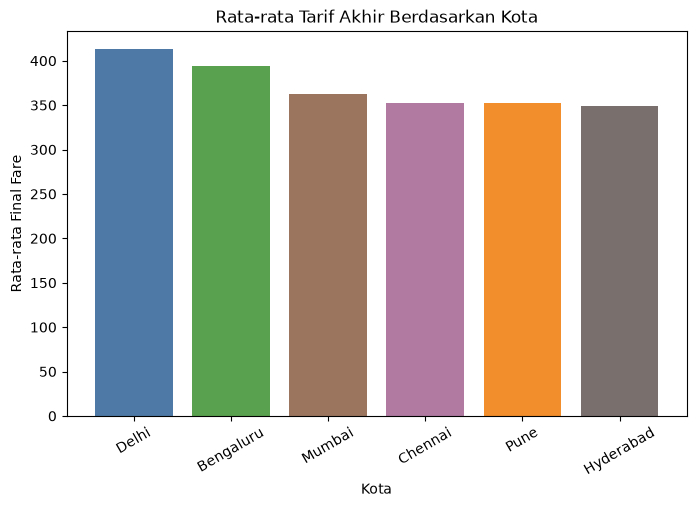

In [31]:
# ================= RATA RATA TARIF AKHIR BERDASARKAN KOTA =====================

city_mean = (
    df.groupby("City")["Final_Fare"]
    .mean()
    .sort_values(ascending=False)
)

print(city_mean)

plt.figure(figsize=(8, 5))

colors = [
    "#4E79A7", 
    "#59A14F", 
    "#9C755F", 
    "#B07AA1", 
    "#F28E2B",  
    "#79706E"   
]

plt.bar(city_mean.index, city_mean.values, color=colors)

plt.title("Rata-rata Tarif Akhir Berdasarkan Kota")
plt.xlabel("Kota")
plt.ylabel("Rata-rata Final Fare")
plt.xticks(rotation=30)

plt.show()

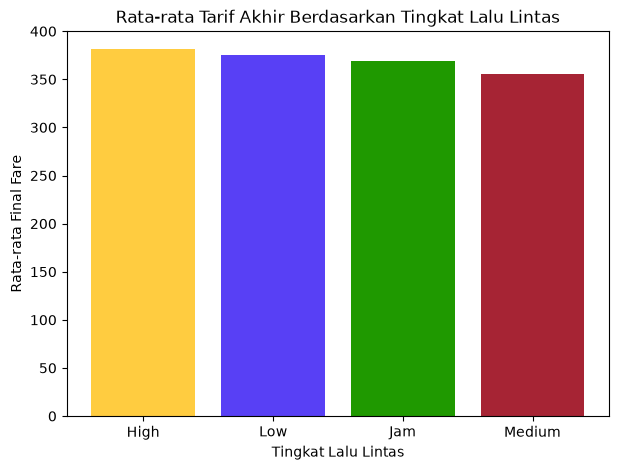

In [32]:
# ============ Rata-rata Tarif Akhir Berdasarkan Tingkat Lalu Lintas ===========

traffic_mean = (
    df.groupby("Traffic_Level")["Final_Fare"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))

colors = ["#ffcc40", "#5840f5", "#1f9900", "#a62434"]

plt.bar(traffic_mean.index, traffic_mean.values, color=colors)

plt.title("Rata-rata Tarif Akhir Berdasarkan Tingkat Lalu Lintas")
plt.xlabel("Tingkat Lalu Lintas")
plt.ylabel("Rata-rata Final Fare")

plt.show()

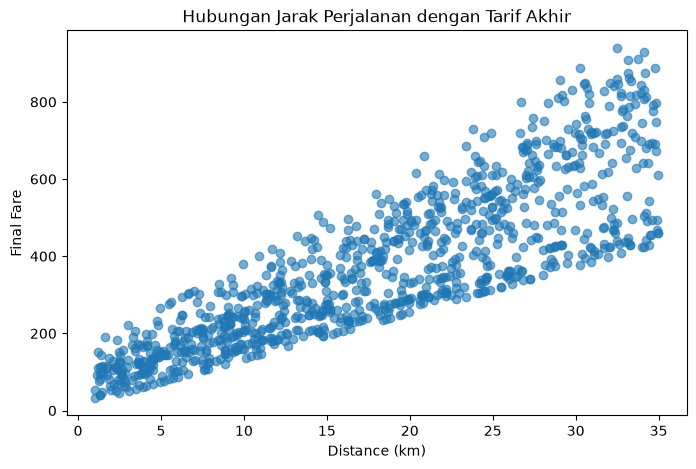

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Distance_km"],
    df["Final_Fare"],
    alpha=0.6
)

plt.title("Hubungan Jarak Perjalanan dengan Tarif Akhir")
plt.xlabel("Distance (km)")
plt.ylabel("Final Fare")

plt.show()

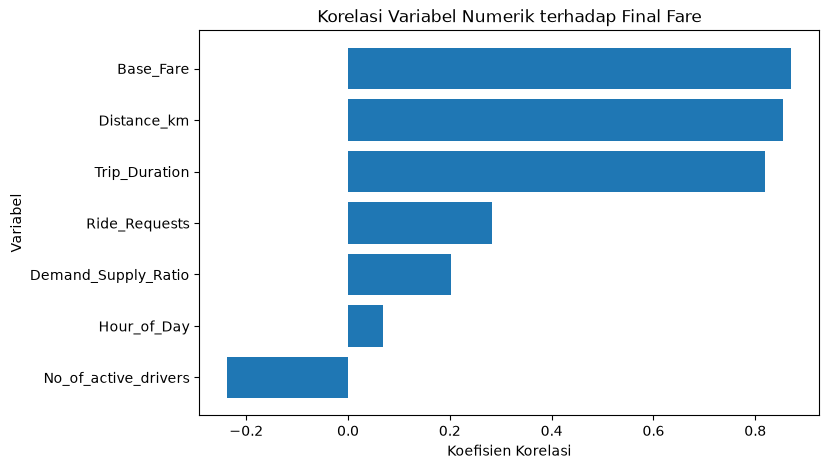

In [34]:
numeric_cols = df.select_dtypes(
    include="number"
).columns

correlation = (
    df[numeric_cols]
    .corr()["Final_Fare"]
    .drop(["Final_Fare", "Surge_Multiplier"])
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 5))

plt.barh(
    correlation.index,
    correlation.values
)

plt.title("Korelasi Variabel Numerik terhadap Final Fare")
plt.xlabel("Koefisien Korelasi")
plt.ylabel("Variabel")

plt.show()

=============== PREPROCESSING DATA ==================

In [35]:
# Cek missing value
missing_values = df.isnull().sum()

print("Missing value:")
print(missing_values[missing_values > 0])

Missing value:
Driver_Name    15
dtype: int64


In [36]:
# ========== HAPUS DATA YANG TIDAK DIPERLUKAN ============

df_model = df.drop(
    columns=[
        "User_ID",
        "Driver_Name",
        "Ride_Date",
        "Surge_Multiplier"
    ]
)
print("Kolom setelah penghapusan:")
print(df_model.columns)

print("\nUkuran dataset:")
print(df_model.shape)

Kolom setelah penghapusan:
Index(['City', 'Hour_of_Day', 'Day_of_Week', 'Distance_km', 'Traffic_Level',
       'Type_of_vehicle', 'No_of_active_drivers', 'Ride_Requests',
       'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Final_Fare'],
      dtype='str')

Ukuran dataset:
(1000, 12)


In [37]:
# =============== ENCODING =============

categorical_cols = [
    "City",
    "Day_of_Week",
    "Traffic_Level",
    "Type_of_vehicle"
]

df_model = pd.get_dummies(
    df_model,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print(df_model.head())

print("\nJumlah kolom:")
print(df_model.shape[1])

print(df_model.dtypes)

   Hour_of_Day  Distance_km  No_of_active_drivers  Ride_Requests  \
0            0        26.21                    36             67   
1            2        21.08                     9             17   
2            6        25.34                    94            149   
3            0        26.80                    25            188   
4           10         4.48                    53             34   

   Demand_Supply_Ratio  Trip_Duration  Base_Fare  Final_Fare  City_Bengaluru  \
0                 1.86             60     354.52      460.88               0   
1                 1.89             50     282.96      367.85               0   
2                 1.59             75     344.08      447.30               1   
3                 7.52             76     351.60      562.56               0   
4                 0.64             18     133.76      133.76               0   

   City_Chennai  ...  Day_of_Week_Wednesday  Traffic_Level_High  \
0             0  ...                      0

In [38]:
X = df_model.drop(columns=["Final_Fare"])
y = df_model["Final_Fare"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 29
Jumlah target: 1000


In [39]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["Final_Fare"])
y = df_model["Final_Fare"]

# 70% training, 30% sementara
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training :", X_train.shape)
print("Validation:", X_val.shape)
print("Testing  :", X_test.shape)

Training : (700, 29)
Validation: (150, 29)
Testing  : (150, 29)
